# 05 · Error analysis: two rounds

**Why:** mAP says how much the model gets wrong, not what or why. We trace every mistake on the val set to the data, the labelling rules or the settings, turn that into hypotheses for A and B, and check what their changes did.

- **Round 1 (8 Nov, E1 at 640):** the ball was the weak class (AP50 0.521); 10 of 11 missed balls had no box at all; most other mistakes were riders and bikes overlapping in crowds. Seven hypotheses (§10).
- **Tried:** a bigger image size, NMS 0.5, a higher bike and player threshold in the app.
- **Round 2 (14 Nov, E2 at 960):** ball AP50-95 0.262 → 0.409 over 3 seeds, 2 more balls found, no more double rider boxes. Hidden balls and crowds remain: they need more data.

**Run:** *Run All*. Needs the two weight files in `models/` (`archive/E1_yolo26s_640_v1b.pt` for round 1, `best.pt` for round 2) and `data/cycle-ball-dataset/` (`python tools/prepare_dataset.py`). Output goes to `runs/error_analysis/` and `reports/error_analysis/` (not in git).

**Author:** Ryan Omondi (error analysis, role C)

> **GenAI:** AI wrote the code and a first draft of the text from my task list. Checks: the scores match B's log (round 1 exactly, round 2 within 0.005); every number in the text comes from an output or from B's log; remarks on pictures are by eye. An independent review found a broken mix-up count, a circular argument about the crowded frames and single-seed numbers presented as the result; all fixed.

## Settings
Both models on the same 25 val frames, each at its training image size.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou

ROOT = Path.cwd().parent                        # this notebook lives in notebooks/
DATA = ROOT / "data/cycle-ball-dataset"         # dataset v1b: 48 train / 25 val (frames 1-234), the same in both rounds
RUNS = ROOT / "runs/error_analysis"             # Ultralytics output (not in git)
REPORTS_DIR = ROOT / "reports/error_analysis"   # figures for the report (not in git: they show video frames)
MODELS = {                                      # round: (weights file, image size it was trained at)
    "round 1": ("models/archive/E1_yolo26s_640_v1b.pt", 640),   # E1-26v1b, seed 0: the first fine-tune
    "round 2": ("models/best.pt", 960),                         # E2-960, seed 0: the champion after the image-size test (notebook 04)
}
CONF = 0.25          # a box counts from this confidence, as in models/detections.csv
IOU_HIT = 0.5        # overlap with a label of the same class that makes a hit (the "50" in mAP50)
IOU_NEAR = 0.1       # between this and IOU_HIT: the right object, but a badly placed box
TIGHT = 0.75         # a hit under this IoU is loose: it counts at AP50, not at the stricter levels of AP50-95
W, H = 3024, 1078                               # every frame of our video
XY = ["x1", "y1", "x2", "y2"]                   # box corners in pixels
DEVICE = 0 if torch.cuda.is_available() else "cpu"   # not mps: batched validation on mps gave wrong mAP here (0.41 instead of 0.91)

RUNS.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
models = {}
for name, (weights, _) in MODELS.items():
    models[name] = YOLO(ROOT / weights)
names = models["round 1"].names                 # {0: 'player', 1: 'ball', 2: 'bike', 3: 'goal'}
iou = lambda a, b: box_iou(torch.tensor(np.asarray(a, float)), torch.tensor(np.asarray(b, float))).numpy()

## 1. Scores

B ran each setting with three seeds (the report):

| From B's log | Round 1 (640) | Round 2 (960) |
|---|---|---|
| Selection metric (mean AP50-95 of ball, player, bike) | 0.468 ± 0.012 | 0.528 ± 0.014 |
| Ball AP50-95, seeds 0 / 1 / 2 | 0.226 / 0.285 / 0.275 (mean 0.262) | 0.422 / 0.421 / 0.385 (mean 0.409) |

Below are the two seed-0 models: the weakest 640 run and the strongest 960 run, so their gap is larger than the average.

In [2]:
scores = {}
for name, (_, size) in MODELS.items():
    r = models[name].val(data=str(DATA / "data.yaml"), imgsz=size, device=DEVICE, plots=False, verbose=False,
                         project=str(RUNS), name=f"val_{size}", exist_ok=True)
    for metric, values, overall in (("AP50", r.box.ap50, r.box.map50), ("AP50-95", r.box.ap, r.box.map)):
        scores[(metric, name)] = {names[c]: v for c, v in zip(r.box.ap_class_index, values)} | {"all": overall}
pd.DataFrame(scores).round(3)

Ultralytics 8.4.193 🚀 Python-3.11.14 torch-2.15.0 CPU (Apple M5)


YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1763.0±162.3 MB/s, size: 457.5 KB)


val: Scanning data/cycle-ball-dataset/labels/val... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 2.5Kit/s 0.0s

val: New cache created: data/cycle-ball-dataset/labels/val.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 1.5s/it 0.5s<1.5s

... (8 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4it/s 1.4s

                   all         25        261      0.932      0.879      0.914      0.652


Speed: 0.2ms preprocess, 48.0ms inference, 0.0ms loss, 0.1ms postprocess per image


,AP50,AP50-95,AP50,AP50-95
,round 1,round 1,round 2,round 2
player,0.934,0.552,0.959,0.568
ball,0.521,0.226,0.755,0.419
bike,0.910,0.587,0.948,0.627
goal,0.995,0.995,0.995,0.995
all,0.840,0.590,0.914,0.652


**Findings:** the ball gains most (AP50 0.521 → 0.755, AP50-95 0.226 → 0.419); player and bike a little; `goal` stays at 0.995. Ball AP50 rises more than the 2 extra balls in §3 suggest, because AP also counts weak boxes under 0.25 (§4).

## 2. What the model confuses

Confusion matrices at confidence 0.25: columns are the true class, rows the prediction; *background* = a missed label (row) or an extra box (column).

In [3]:
classes = list(names.values()) + ["background"]
for name, (_, size) in MODELS.items():
    m = models[name].val(data=str(DATA / "data.yaml"), imgsz=size, conf=CONF, device=DEVICE, verbose=False,
                         project=str(RUNS), name=f"val_{size}_conf", exist_ok=True).confusion_matrix.matrix.astype(int)
    print(f"{name}: {m[:4, :4].sum() - np.trace(m[:4, :4])} class mix-up(s)")
    display(pd.DataFrame(m, index=[f"pred {c}" for c in classes], columns=[f"true {c}" for c in classes]))

Ultralytics 8.4.193 🚀 Python-3.11.14 torch-2.15.0 CPU (Apple M5)


YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 11495.5±2108.8 MB/s, size: 454.2 KB)


val: Scanning data/cycle-ball-dataset/labels/val.cache... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 35.0Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 1.3s/it 0.4s<1.3s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.2it/s 0.6s

... (12 outputs left out)

Speed: 1.0ms preprocess, 42.3ms inference, 0.0ms loss, 0.1ms postprocess per image


Results saved to runs/error_analysis/val_960_conf


round 2: 2 class mix-up(s)


,true player,true ball,true bike,true goal,true background
pred player,90,0,0,0,5
pred ball,0,17,0,0,2
pred bike,2,0,87,0,17
pred goal,0,0,0,50,0
pred background,5,8,2,0,0


**Findings:** almost no mix-ups (1 in round 1, 2 in round 2): the mistakes are about finding and placing boxes. Missed balls 10 → 8; extra boxes for bike 23 → 17, player 9 → 5, ball 6 → 2.

## 3. Every box matched to a label

Boxes from 0.25, highest first, each take the best free label of their class; IoU ≥ 0.5 is a hit. Extra box (FP): *duplicate*, *poor box* (IoU 0.1–0.5) or *nothing there*. Missed label (FN): *low confidence* (a good box under 0.25), *poor box*, or *not seen* (neither).

In [4]:
def read_labels(split):
    rows = []
    for path in sorted((DATA / "labels" / split).glob("*.txt")):
        for line in path.read_text().splitlines():
            c, x, y, w, h = map(float, line.split())
            rows.append([int(path.stem[6:]), names[int(c)], (x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H])
    return pd.DataFrame(rows, columns=["frame", "cls", *XY])


def predict(name):
    rows = []
    for path in sorted((DATA / "images/val").glob("*.jpg")):
        boxes = models[name].predict(path, imgsz=MODELS[name][1], conf=0.01, device=DEVICE, verbose=False)[0].boxes
        rows += [[int(path.stem[6:]), names[int(c)], p, *xyxy] for c, p, xyxy in zip(boxes.cls.tolist(), boxes.conf.tolist(), boxes.xyxy.tolist())]
    return pd.DataFrame(rows, columns=["frame", "cls", "conf", *XY])


def match(preds, conf=CONF):
    """Every label as TP or FN (with the IoU of its hit), every extra box as FP, each with its type."""
    rows = []
    for frame, gt in labels.groupby("frame"):
        pr = preds[preds.frame == frame].sort_values("conf", ascending=False)
        overlap = iou(pr[XY], gt[XY])
        overlap[pr.cls.to_numpy()[:, None] != gt.cls.to_numpy()] = 0    # a box can only match a label of its own class
        kept = (pr.conf >= conf).to_numpy()
        hit = np.full(len(gt), np.nan)
        for i in np.flatnonzero(kept):
            free = np.where(np.isnan(hit), overlap[i], 0)
            if free.max() >= IOU_HIT:
                hit[free.argmax()] = free.max()
            else:
                best = overlap[i].max()
                kind = "duplicate" if best >= IOU_HIT else "poor box" if best >= IOU_NEAR else "nothing there"
                rows.append([frame, pr.cls.iat[i], "FP", kind, np.nan, *pr[XY].iloc[i]])
        for j, column in enumerate(overlap.T):
            found = not np.isnan(hit[j])
            kind = ("" if found else "low confidence" if (column[~kept] >= IOU_HIT).any()
                    else "poor box" if (column[kept] >= IOU_NEAR).any() else "not seen")
            rows.append([frame, gt.cls.iat[j], "TP" if found else "FN", kind, hit[j], *gt[XY].iloc[j]])
    return pd.DataFrame(rows, columns=["frame", "cls", "result", "kind", "iou", *XY])


labels = read_labels("val")
preds = {name: predict(name) for name in MODELS}
results = {name: match(preds[name]) for name in MODELS}
display(pd.concat({name: r.groupby(["cls", "result"]).size().unstack(fill_value=0)[["TP", "FN", "FP"]] for name, r in results.items()}, axis=1))
pd.concat({name: r[r.result != "TP"].groupby(["cls", "result", "kind"]).size() for name, r in results.items()}, axis=1).fillna(0).astype(int)

round 1         round 2       
result      TP  FN  FP      TP FN  FP
cls                                  
ball        14  11   4      16  9   3
bike        81   8  28      85  4  20
goal        50   0   0      50  0   0
player      90   7  12      90  7   4

round 1  round 2
cls    result kind                            
ball   FN     not seen             10        5
              poor box              1        0
       FP     duplicate             2        1
              poor box              2        1
bike   FN     low confidence        5        3
              poor box              3        1
       FP     duplicate             5        2
              poor box             23       17
player FN     low confidence        3        5
              poor box              4        2
       FP     duplicate             6        0
              poor box              6        4
ball   FN     low confidence        0        4
       FP     nothing there         0        1
bike   FP     nothing there         0        1

**Findings:**
- **Ball:** found 14 → 16 of 25; *not seen* 10 → 5, but the 4 new *low confidence* misses only have a weak box (§4).
- **Bike:** found 81 → 85 of 89; extra boxes 28 → 20, mostly poor boxes (seen, but split or cut off).
- **Player:** found 90 of 97 in both; extra boxes 12 → 4, duplicates 6 → 0; none on *nothing* (no spectator, official or referee boxed).
- **Goal:** perfect in both.

## 4. The ball

All 25 val balls. `touching` = how many rider or bike labels the ball's label overlaps: how crowded it is.

In [5]:
def touching(frame_labels, box):
    riders = frame_labels[frame_labels.cls.isin(["player", "bike"])]
    return int((iou([box], riders[XY]) > 0).sum())


ball = {name: r[(r.cls == "ball") & (r.result != "FP")].set_index("frame") for name, r in results.items()}
balls = ball["round 1"][XY].assign(touching=[touching(labels[labels.frame == f], b) for f, b in ball["round 1"][XY].iterrows()])
for name in MODELS:
    balls[name] = (ball[name].result + " " + ball[name].kind).str.strip()
display(balls[["touching", *MODELS]])

balls["crowding"] = pd.cut(balls.touching, [-1, 1, 2, 9], labels=["0-1 boxes", "2 boxes", "3+ boxes"])
display(pd.DataFrame({"balls": balls.groupby("crowding", observed=True).size()} |
                     {f"found, {name}": (balls[name] == "TP").groupby(balls.crowding, observed=True).sum() for name in MODELS}))

weak = {}
for frame in balls.index[balls["round 2"] == "FN low confidence"]:
    p = preds["round 2"][(preds["round 2"].frame == frame) & (preds["round 2"].cls == "ball")]
    weak[frame] = round(p.conf[iou(p[XY], [balls.loc[frame, XY]])[:, 0] >= IOU_HIT].max(), 2)
print("round 2, low-confidence misses, best box at IoU >= 0.5:", weak)

width = balls.x2 - balls.x1
print("median label width (px in the 3024 px frame), found / missed:",
      {name: (width[balls[name] == "TP"].median().round(), width[balls[name] != "TP"].median().round()) for name in MODELS})
train = read_labels("train")
crowded = sum(touching(train[train.frame == b.frame], b[XY]) >= 2 for _, b in train[train.cls == "ball"].iterrows())
print(f"balls touching 2+ rider or bike labels: val {(balls.touching >= 2).sum()} of {len(balls)}, train {crowded} of {(train.cls == 'ball').sum()}")

,touching,round 1,round 2
frame,,,
13,2,FN not seen,FN not seen
22,2,FN not seen,FN not seen
32,1,TP,TP
34,1,TP,TP
39,2,FN not seen,FN low confidence
47,3,FN poor box,FN low confidence
53,3,FN not seen,FN not seen
60,4,FN not seen,FN not seen
65,2,FN not seen,FN not seen


,balls,"found, round 1","found, round 2"
crowding,,,
0-1 boxes,8,8,8
2 boxes,13,6,7
3+ boxes,4,0,1


round 2, low-confidence misses, best box at IoU >= 0.5: {39: np.float64(0.03), 47: np.float64(0.19), 74: np.float64(0.09), 137: np.float64(0.15)}
median label width (px in the 3024 px frame), found / missed: {'round 1': (np.float64(36.0), np.float64(42.0)), 'round 2': (np.float64(36.0), np.float64(42.0))}
balls touching 2+ rider or bike labels: val 17 of 25, train 9 of 48


**Findings:**
- **Crowding decides:** touching 0–1: 8 of 8 found in both rounds; 2: 6 → 7 of 13; 3 or more: 0 → 1 of 4.
- **Round 2 finds 80 and 102,** visible next to a foot or wheel. 39, 47, 74 and 137 only have weak boxes (0.03–0.19). 13, 22, 60 and 65 are missed in both: hidden by wheels or feet, and blurred.
- **Size:** found and missed balls have the same label size (36 and 42 px), but every ball is about 7 px at 640 and 10 px at 960; the two that came back are visible ones.
- **Train is less crowded:** 9 of 48 train balls touch 2 or more riders or bikes, against 17 of 25 val balls.
- **Labelling rules:** half-hidden and blurred balls are labelled, so every miss in a crowd counts.
- **Doubtful labels:** 53 (box on a rider's head, also in video frames 51–55) and 74 (on a shoe); B flagged the same two.

## 5. Box tightness

IoU of every hit, and the share under 0.75 (loose). For the ball also only the balls both rounds hit.

In [6]:
tight = pd.concat({name: r[r.result == "TP"].groupby("cls").iou.agg(hits="size", mean_iou="mean", loose=lambda s: (s < TIGHT).mean())
                   for name, r in results.items()}, axis=1)
display(tight.round(2))
both = ball["round 1"].index[(ball["round 1"].result == "TP") & (ball["round 2"].result == "TP")]
print(f"the {len(both)} balls both rounds hit, mean IoU:", {name: ball[name].loc[both, "iou"].mean().round(2) for name in MODELS})

round 1                round 2               
          hits mean_iou loose    hits mean_iou loose
cls                                                 
ball        14     0.72  0.50      16     0.80  0.38
bike        81     0.81  0.23      85     0.82  0.24
goal        50     0.98  0.00      50     0.98  0.00
player      90     0.81  0.24      90     0.80  0.31

the 14 balls both rounds hit, mean IoU: {'round 1': np.float64(0.72), 'round 2': np.float64(0.81)}


**Findings:** ball boxes are tighter: 0.72 → 0.81 on the same 14 balls, loose 50% → 38%. Bikes about the same; player boxes not tighter (loose 24% → 31%).

## 6. Bikes and the occlusion rule

A bike more than half hidden gets no box. Do the extra bike boxes gather in frames with fewer bike than rider labels?

In [7]:
per_frame = labels.groupby(["frame", "cls"]).size().unstack(fill_value=0)
hidden = per_frame.index[per_frame.bike < per_frame.player]
print("val frames with fewer bike than rider labels:", list(hidden))
pd.DataFrame({name: {"extra bike boxes in those frames": r[(r.cls == "bike") & (r.result == "FP") & r.frame.isin(hidden)].shape[0],
                     "extra bike boxes, other frames": r[(r.cls == "bike") & (r.result == "FP") & ~r.frame.isin(hidden)].shape[0]}
              for name, r in results.items()})

val frames with fewer bike than rider labels: [22, 32, 34, 39, 53, 80, 102]


,round 1,round 2
extra bike boxes in those frames,8,6
"extra bike boxes, other frames",20,14


**Findings:** no. Those 7 frames (the same as in the EDA) hold 8 of 28 extra bike boxes in round 1 and 6 of 20 in round 2, about their share of the frames (7 of 25). The extra boxes are poor boxes on labelled bikes.

## 7. Worst frames

Mistakes per val frame: the lecturer's *top losses*.

worst 5 frames: {'round 1': {80: 9, 137: 9, 102: 7, 47: 5, 53: 5}, 'round 2': {137: 7, 53: 4, 60: 4, 74: 4, 80: 4}}


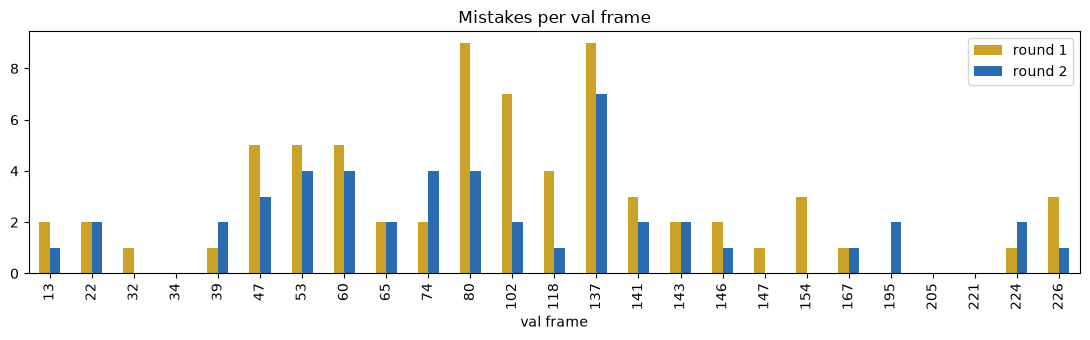

In [8]:
mistakes = pd.DataFrame({name: r[r.result != "TP"].groupby("frame").size() for name, r in results.items()}
                        ).reindex(sorted(labels.frame.unique())).fillna(0).astype(int)
print("worst 5 frames:", {name: mistakes[name].nlargest(5).to_dict() for name in MODELS})
ax = mistakes.plot.bar(figsize=(11, 3.5), title="Mistakes per val frame", color=["#c9a227", "#2b6cb0"])
ax.set_xlabel("val frame")
ax.figure.tight_layout()
ax.figure.savefig(REPORTS_DIR / "mistakes_per_frame.png", dpi=120)
plt.show()

**Findings:** fewer mistakes in most frames (80: 9 → 4, 102: 7 → 2), a few more in 39, 74, 195 and 224. The five worst frames of both rounds all have a crowded ball (touching 2 or more).

## 8. Confidence per class

F1 at four thresholds. With 25 frames this is a direction, not a final value.

In [9]:
rows = []
for name in MODELS:
    for threshold in (0.1, 0.25, 0.4, 0.5):
        n = match(preds[name], threshold).groupby(["cls", "result"]).size().unstack(fill_value=0)
        rows += [[name, threshold, c, round(2 * n.at[c, "TP"] / (2 * n.at[c, "TP"] + n.at[c, "FP"] + n.at[c, "FN"]), 3)] for c in ("ball", "player", "bike")]
pd.DataFrame(rows, columns=["round", "threshold", "class", "F1"]).pivot(index="threshold", columns=["class", "round"], values="F1")

class,ball,player,bike,ball,player,bike
round,round 1,round 1,round 1,round 2,round 2,round 2
threshold,,,,,,
0.10,0.560,0.860,0.725,0.679,0.916,0.784
0.25,0.651,0.905,0.818,0.727,0.942,0.876
0.40,0.651,0.916,0.824,0.684,0.936,0.890
0.50,0.632,0.921,0.842,0.684,0.935,0.874


**Findings:** the ball is best at 0.25. In round 1 player and bike were best at 0.5, which the app uses; round 2 is best at player 0.25 and bike 0.4, so the app's thresholds need redoing for the new model, ideally on a test set.

## 9. Gallery

Green: labels, red: boxes from 0.25. First the balls that changed or are still missed (left round 1, right round 2), then round 2's remaining player and bike mistakes.

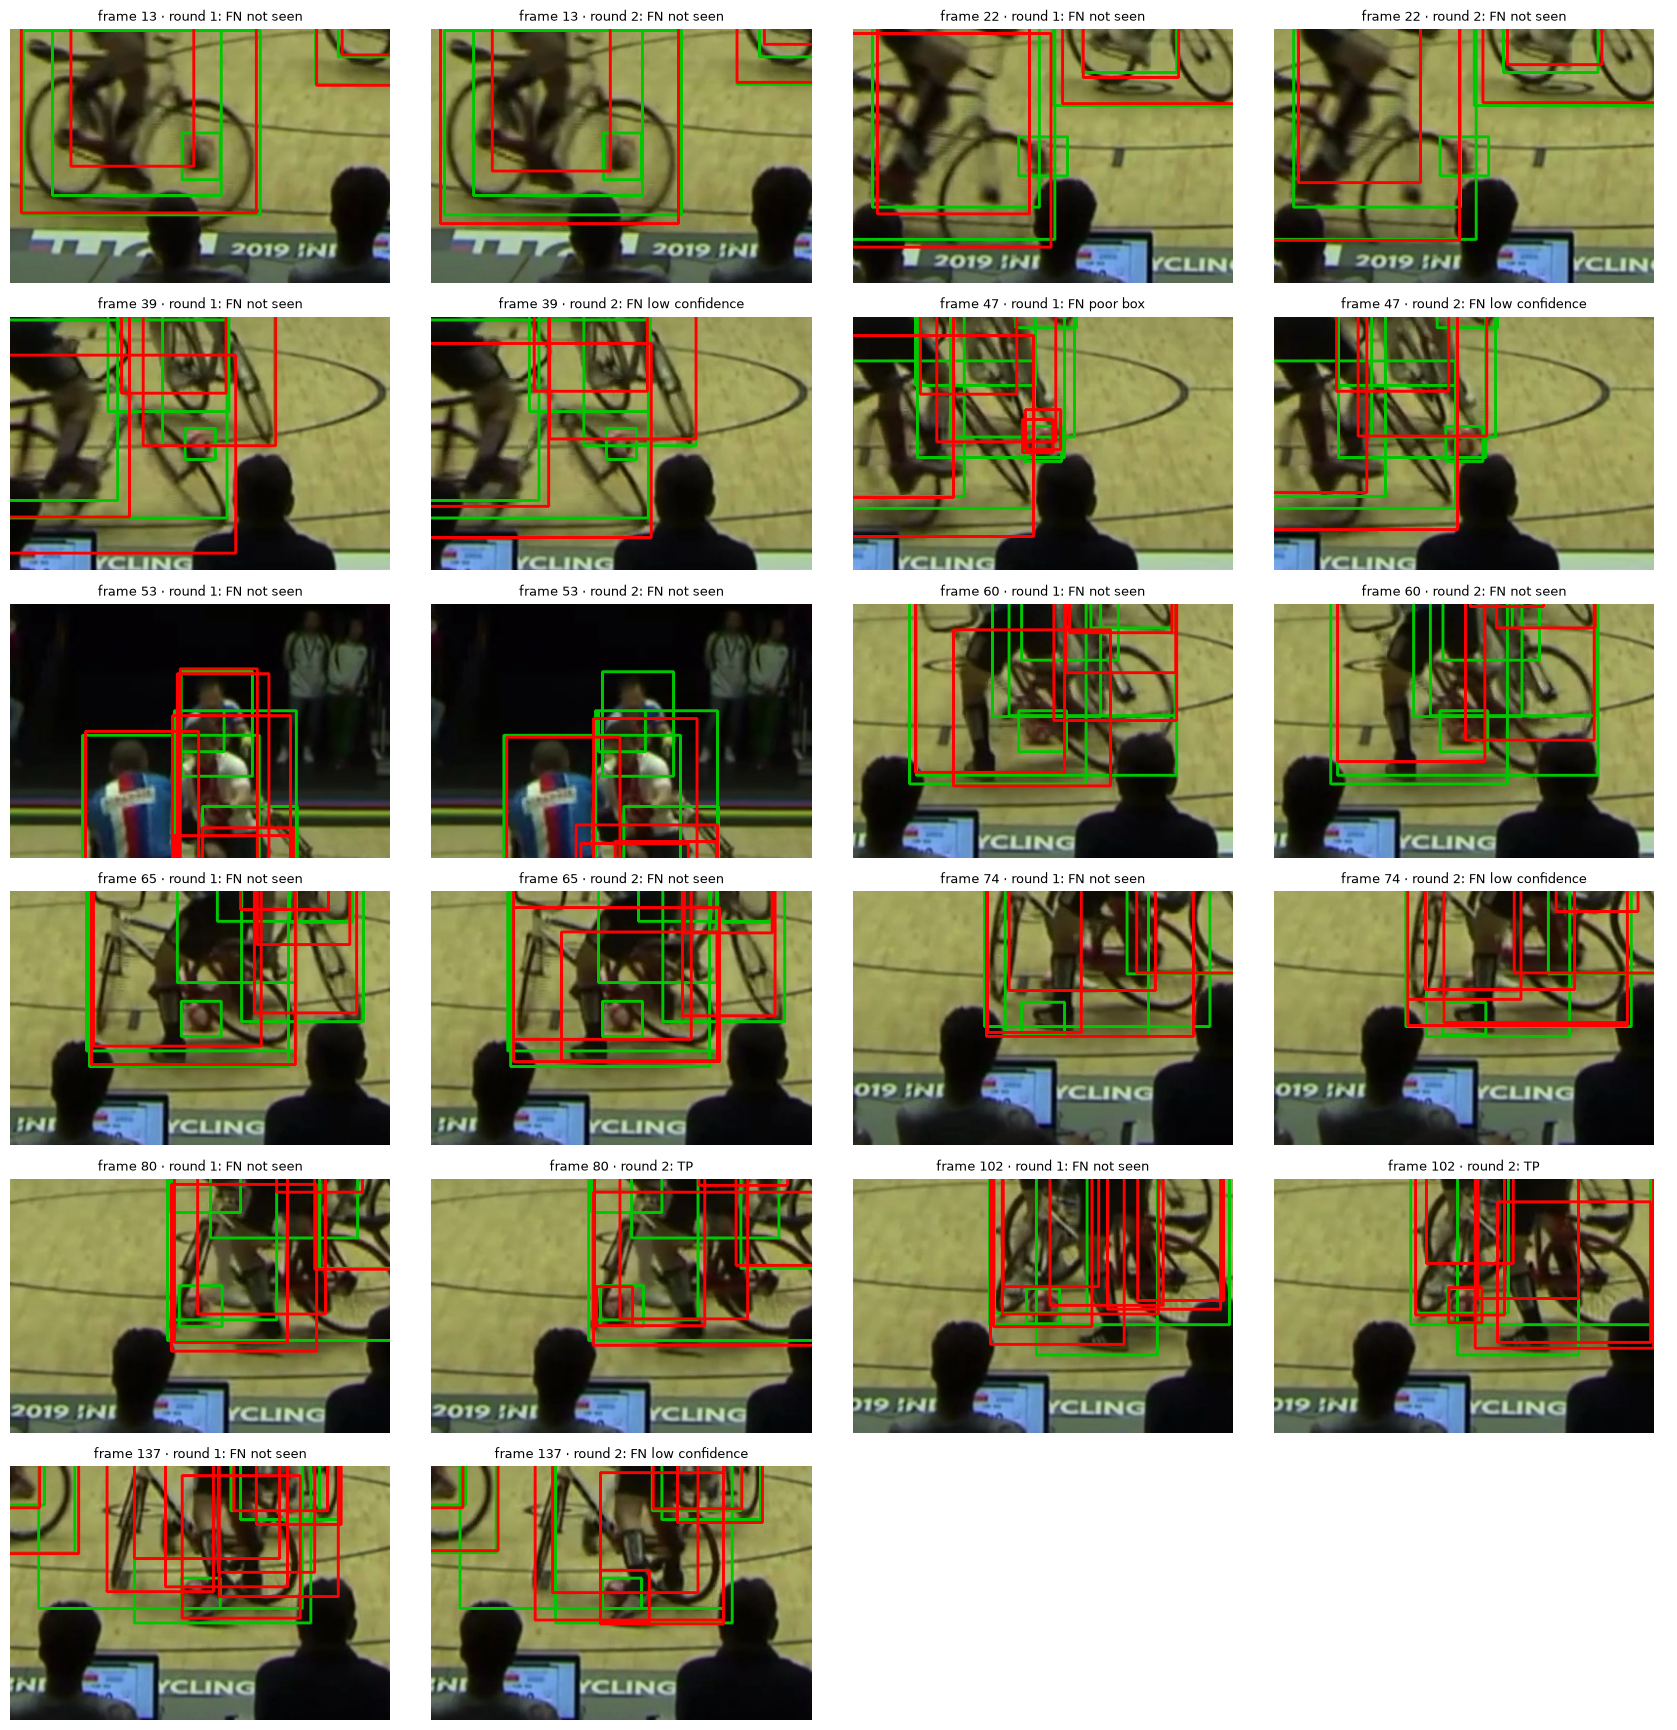

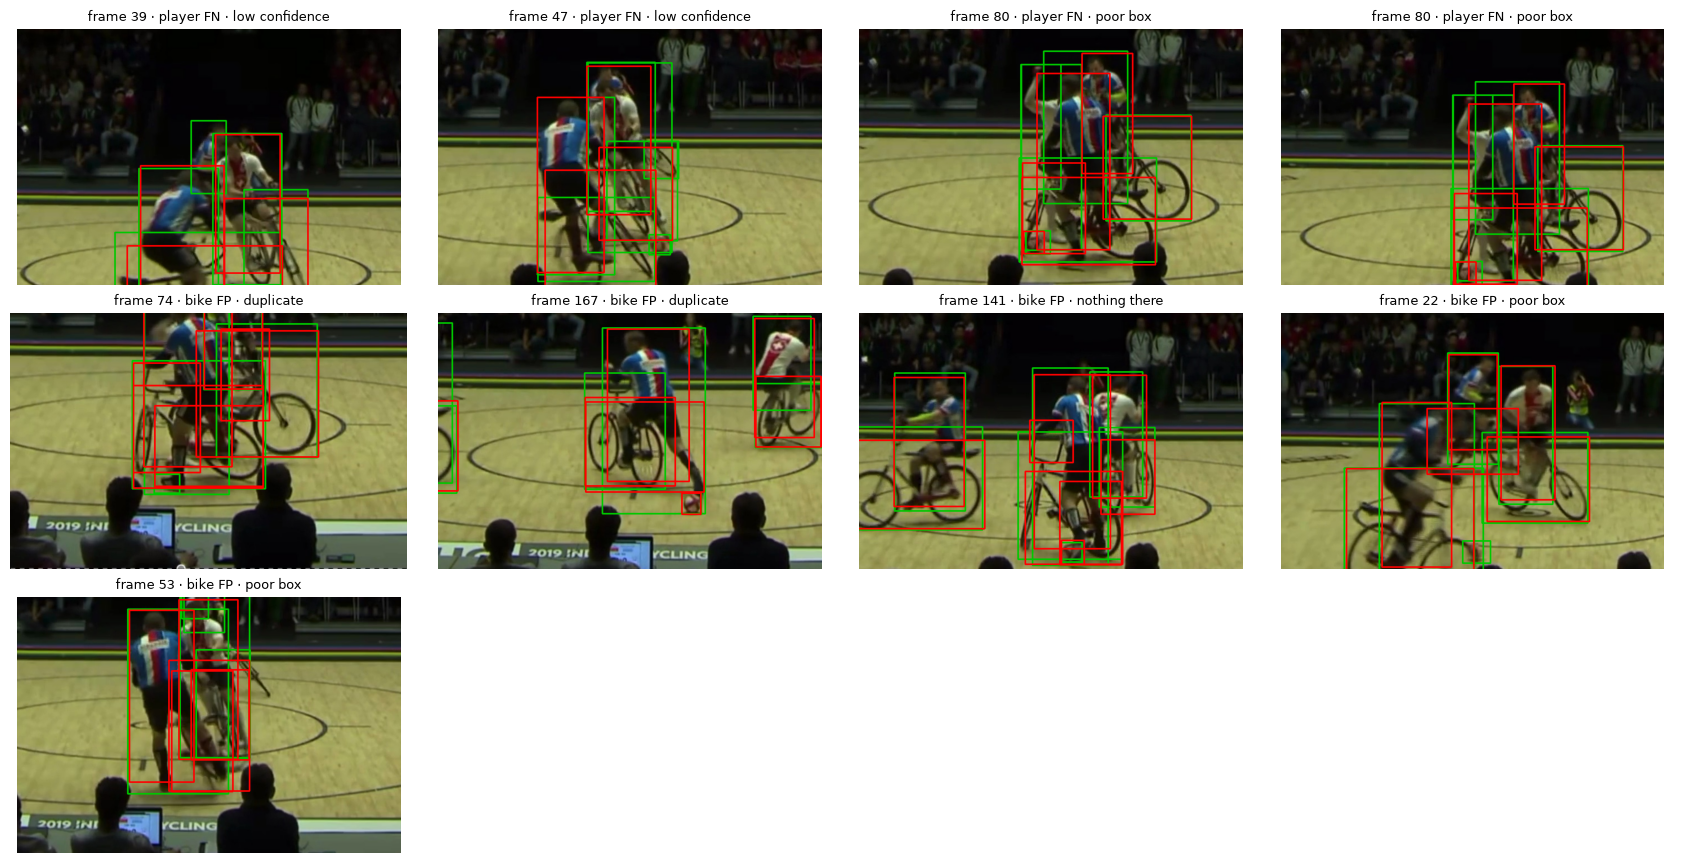

In [10]:
def crop(name, frame, box, half):
    image = cv2.imread(str(DATA / "images/val" / f"frame_{frame:05d}.jpg"))
    for boxes, colour in ((labels[labels.frame == frame], (0, 200, 0)), (preds[name][(preds[name].frame == frame) & (preds[name].conf >= CONF)], (0, 0, 255))):
        for x1, y1, x2, y2 in boxes[XY].to_numpy().astype(int):
            cv2.rectangle(image, (x1, y1), (x2, y2), colour, 2)
    cx, cy = int(box.x1 + box.x2) // 2, int(box.y1 + box.y2) // 2
    return cv2.cvtColor(image[max(0, cy - half):cy + half, max(0, cx - 3 * half // 2):cx + 3 * half // 2], cv2.COLOR_BGR2RGB)


def gallery(panels, half, file_name):
    """panels: (round, frame, box, title); 4 per row."""
    fig, axes = plt.subplots((len(panels) + 3) // 4, 4, figsize=(17, 2.9 * ((len(panels) + 3) // 4)))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (name, frame, box, title) in zip(axes.flat, panels):
        ax.imshow(crop(name, frame, box, half))
        ax.set_title(title, fontsize=9)
    fig.tight_layout()
    fig.savefig(REPORTS_DIR / file_name, dpi=110)
    plt.show()


shown = balls.index[(balls["round 2"] == "TP") & (balls["round 1"] != "TP") | (balls["round 2"] != "TP")]
gallery([(name, f, balls.loc[f], f"frame {f} · {name}: {balls.loc[f, name]}") for f in shown for name in MODELS], 130, "ball_rounds.png")
left = results["round 2"][results["round 2"].cls.isin(["player", "bike"]) & (results["round 2"].result != "TP")]
gallery([("round 2", r.frame, r, f"frame {r.frame} · {r.cls} {r.result} · {r.kind}")
         for _, r in left.sort_values(["result", "kind", "frame"]).groupby(["result", "kind"]).head(2).iterrows()], 230, "rider_mistakes_round2.png")

**Findings** (by eye): in 80 and 102 round 2 boxes the ball; in 13, 22, 60 and 65 the ball is against a wheel or feet and blurred. Round 2's remaining player and bike mistakes are almost all riders overlapping in a group (22, 39, 47, 53, 74, 80), plus a small bike box on a rider (141).

## 10. Hypotheses: round 1 → tried → round 2

| # | Round 1: mistake → fix | Tried | Round 2 | Status |
|---|---|---|---|---|
| 1 | Ball missed in crowds → more crowded training frames (A) | not yet | 2 more found, 4 hidden balls still missed (§4) | **Open:** the main ball problem |
| 2 | Loose ball boxes → bigger image size (B) | 640 / 960 / 1280 (in B's plan; round 1 set the target) | IoU 0.72 → 0.81 on the same balls (§5); ball AP50-95 0.262 → 0.409 over 3 seeds; 1280 no better | **Confirmed** at 960 |
| 3 | Doubtful labels in 53 and 74 → check the video (A) | not yet | still missed (§4) | **Open** |
| 4 | Split bike boxes → more crowded frames (A) | not yet | extra bike boxes 28 → 20; not from hidden bikes (§6) | **Improved** |
| 5 | Extra bike boxes on the map → higher threshold (B, D) | app: bike and player at 0.5 | round 2 is best at bike 0.4, player 0.25 (§8) | **Redo** for round 2 |
| 6 | Double rider boxes → NMS 0.5 (B) | tested | refuted: player AP50 0.934 → 0.897 (B's log); gone anyway in round 2 (§3) | **Gone** (one seed) |
| 7 | Referee in a player box → label such frames (A) | not yet | no referee boxed in val (§3); shows in the full video (notebook 06) | **Open** |

## Conclusions

- **What worked:** the bigger image size (hypothesis 2): tighter ball boxes, ball AP50-95 0.262 → 0.409 over 3 seeds. NMS 0.5 (hypothesis 6) was tested and refuted.
- **Round 1 was partly wrong:** size does not separate found from missed balls, but 7 px at 640 did hold back visible balls in a crowd.
- **Where we are:** the ball is still the weakest class (AP50 0.755, against 0.948 or more). The balls still missed are hidden, and training has few crowded balls, so the next gain has to come from data (A).
- **Next:** add the dataset v2 model to `MODELS` and run again. `detections.csv` and `teams.csv` are already redone at 960 (`tools/make_detections.py`, notebook 06). The app's thresholds (player and bike 0.5) are still round 1's; §8 suggests lower for round 2, to be chosen on a test set.